# Conecta Sangue — Disciplina 4: Pesquisa Operacional (Python)

**Projeto em Gestão de Sistemas Computacionais · 2026**

Este notebook usa programação linear inteira para provar matematicamente qual é a melhor decisão para a Conecta Sangue diante de recursos limitados de tempo, dinheiro e equipe. São dois problemas distintos, cada um com contexto, variáveis de decisão, função objetivo, restrições, código, resultado e análise de cenário (What-If):

| Problema | Tipo | Decisão |
|---|---|---|
| 4.1 | Maximização de lucro | Quantas implantações de cada plano da plataforma aceitar no mês |
| 4.2 | Minimização de custos (transporte) | Como distribuir os agentes de cadastro entre os mutirões das campanhas presenciais |

**Regra da disciplina:** a modelagem e a resolução são feitas em Python, com a biblioteca **PuLP** (resolvedor CBC). O Excel Solver não é usado. No fim, uma célula confere os resultados com um segundo resolvedor (`scipy.optimize.milp`).

**Como executar:** no Google Colab, use *Ambiente de execução → Executar tudo*. A primeira célula instala o PuLP; as demais bibliotecas já vêm no Colab. Os gráficos são salvos na pasta `graficos/`.

**Premissas:** a disciplina pede que o grupo crie os próprios números e o contexto. Os valores de lucro, horas e custos são premissas do grupo; a demanda do Problema 2 e as localizações vêm da base de dados da Disciplina 2.

In [1]:
!pip install pulp

In [2]:
# Bibliotecas utilizadas
import math
import os
import pandas as pd
import matplotlib.pyplot as plt
from pulp import LpProblem, LpMaximize, LpMinimize, LpVariable, lpSum, LpStatus, value, PULP_CBC_CMD

pd.set_option('display.width', 130)
os.makedirs('graficos', exist_ok=True)


def brl(v):
    """Formata um valor em reais: 85000 -> 'R$ 85.000,00'."""
    return 'R$ ' + f'{v:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


# Estilo dos gráficos (o mesmo da Disciplina 2)
AZUL, LARANJA, AZUL_CLARO = '#2a78d6', '#eb6834', '#8db9ec'
TEXTO, TEXTO_SECUNDARIO, GRADE = '#0b0b0b', '#52514e', '#e6e5e0'
plt.rcParams.update({
    'figure.dpi': 100, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': '#b5b4ad', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlecolor': TEXTO, 'axes.labelcolor': TEXTO_SECUNDARIO, 'axes.labelsize': 10.5,
    'xtick.color': TEXTO_SECUNDARIO, 'ytick.color': TEXTO_SECUNDARIO, 'font.size': 10.5,
    'legend.frameon': False})


def subtitulo(ax, texto):
    ax.text(0, 1.02, texto, transform=ax.transAxes, fontsize=10, color=TEXTO_SECUNDARIO, va='bottom')


def salvar(fig, nome):
    fig.savefig(f'graficos/{nome}.png', dpi=200, bbox_inches='tight')

## 4.1 Problema 1: Maximização de lucro

**Contexto.** Depois do piloto, a Conecta Sangue vai levar a plataforma a novos hemocentros e hospitais com banco de sangue, em dois planos montados a partir do backlog do protótipo:

* **Plano Essencial:** cadastro de doadores, localização e consulta dos pontos de coleta (US01, US02, US03 e US08).
* **Plano Campanhas:** tudo do Essencial mais campanhas segmentadas por localização e o painel do hemocentro (US04, US05 e US07).

Há mais parceiros interessados do que a equipe consegue atender. Cada implantação consome horas de três equipes limitadas: desenvolvimento e integração, segurança e LGPD (perfis de acesso, registro do tratamento e testes de autorização, definidos na Disciplina 3) e treinamento. O Plano Campanhas consome mais horas de segurança porque trata a localização dos doadores para enviar campanhas. A gerência precisa decidir **quantas implantações de cada plano aceitar no mês para obter o maior lucro possível**.

**Variáveis de decisão** (inteiras):

* $x_E$: quantidade de implantações do Plano Essencial no mês.
* $x_C$: quantidade de implantações do Plano Campanhas no mês.

**Função objetivo** (lucro do mês, em reais):

$$\text{Max } Z = 5000\,x_E + 12000\,x_C$$

**Restrições técnicas:**

| Restrição | Inequação |
|---|---|
| Horas de desenvolvimento e integração | $30\,x_E + 60\,x_C \le 450$ |
| Horas de segurança e LGPD | $4\,x_E + 12\,x_C \le 80$ |
| Horas de treinamento e suporte | $10\,x_E + 12\,x_C \le 140$ |
| Mercado (parceiros interessados) | $x_E \le 12$, $\; x_C \le 8$ |
| Lógica | $x_E, x_C \ge 0$ e inteiros |

In [3]:
# Parâmetros do Problema 1 (premissas do grupo)
LUCRO = {'Essencial': 5000, 'Campanhas': 12000}          # lucro por implantação (R$)
HORAS = {                                                # horas consumidas por implantação
    'Desenvolvimento e integração': {'Essencial': 30, 'Campanhas': 60},
    'Segurança e LGPD':             {'Essencial': 4,  'Campanhas': 12},
    'Treinamento e suporte':        {'Essencial': 10, 'Campanhas': 12},
}
DISPONIVEL = {                                           # horas disponíveis no mês
    'Desenvolvimento e integração': 450,   # 3 desenvolvedores x 150 h
    'Segurança e LGPD': 80,                # metade da jornada de 1 analista de segurança
    'Treinamento e suporte': 140,
}
MERCADO = {'Essencial': 12, 'Campanhas': 8}               # parceiros interessados no mês
NOME_RESTRICAO = {'Desenvolvimento e integração': 'Horas_Desenvolvimento',
                  'Segurança e LGPD': 'Horas_Seguranca_LGPD',
                  'Treinamento e suporte': 'Horas_Treinamento'}

parametros_p1 = pd.DataFrame({
    'Plano Essencial': [LUCRO['Essencial']] + [HORAS[r]['Essencial'] for r in HORAS] + [MERCADO['Essencial']],
    'Plano Campanhas': [LUCRO['Campanhas']] + [HORAS[r]['Campanhas'] for r in HORAS] + [MERCADO['Campanhas']],
    'Disponível no mês': ['—'] + [DISPONIVEL[r] for r in HORAS] + ['—'],
}, index=['Lucro por implantação (R$)'] + [f'{r} (h)' for r in HORAS] + ['Máximo de parceiros interessados'])
display(parametros_p1)

,Plano Essencial,Plano Campanhas,Disponível no mês
Lucro por implantação (R$),5000,12000,—
Desenvolvimento e integração (h),30,60,450
Segurança e LGPD (h),4,12,80
Treinamento e suporte (h),10,12,140
Máximo de parceiros interessados,12,8,—


In [4]:
def resolver_problema1(disponivel=DISPONIVEL, mercado=MERCADO):
    """Monta e resolve o modelo de maximização de lucro. Devolve o modelo e as variáveis."""
    modelo = LpProblem(name='Max_Lucro_Implantacoes', sense=LpMaximize)

    # Variáveis de decisão (inteiras)
    xE = LpVariable(name='Plano_Essencial', lowBound=0, cat='Integer')
    xC = LpVariable(name='Plano_Campanhas', lowBound=0, cat='Integer')

    # Função objetivo: lucro total do mês
    modelo += LUCRO['Essencial'] * xE + LUCRO['Campanhas'] * xC, 'Lucro'

    # Restrições de horas das três equipes
    for recurso, consumo in HORAS.items():
        modelo += (consumo['Essencial'] * xE + consumo['Campanhas'] * xC <= disponivel[recurso],
                   NOME_RESTRICAO[recurso])

    # Restrições de mercado
    modelo += (xE <= mercado['Essencial'], 'Mercado_Essencial')
    modelo += (xC <= mercado['Campanhas'], 'Mercado_Campanhas')

    modelo.solve(PULP_CBC_CMD(msg=False))
    return modelo, xE, xC


def uso_dos_recursos(xE, xC, disponivel=DISPONIVEL):
    """Tabela com as horas usadas, disponíveis e a folga de cada equipe."""
    linhas = []
    for recurso, consumo in HORAS.items():
        usado = consumo['Essencial'] * xE.varValue + consumo['Campanhas'] * xC.varValue
        linhas.append([recurso, usado, disponivel[recurso], disponivel[recurso] - usado])
    return pd.DataFrame(linhas, columns=['Recurso', 'Horas usadas', 'Horas disponíveis', 'Folga']).set_index('Recurso')

In [5]:
# Resolução do cenário base
modelo1, xE, xC = resolver_problema1()
p1_base = {'status': LpStatus[modelo1.status], 'essencial': int(xE.varValue), 'campanhas': int(xC.varValue),
           'lucro': value(modelo1.objective)}

print(f"Status: {p1_base['status']}")
print(f"Implantações do Plano Essencial: {p1_base['essencial']}")
print(f"Implantações do Plano Campanhas: {p1_base['campanhas']}")
print(f"Lucro máximo do mês: {brl(p1_base['lucro'])}")
uso_p1_base = uso_dos_recursos(xE, xC)
display(uso_p1_base)

Status: Optimal
Implantações do Plano Essencial: 5
Implantações do Plano Campanhas: 5
Lucro máximo do mês: R$ 85.000,00


,Horas usadas,Horas disponíveis,Folga
Recurso,,,
Desenvolvimento e integração,450.0,450,0.0
Segurança e LGPD,80.0,80,0.0
Treinamento e suporte,110.0,140,30.0


**Leitura do resultado.** O modelo aceita **5 implantações de cada plano** e chega a **R$ 85.000,00** de lucro no mês. As horas de desenvolvimento e as de segurança e LGPD são usadas por completo (folga zero): são os gargalos. O treinamento ainda tem 30 horas livres. Vender só o plano mais caro não é o melhor caminho: o Plano Campanhas rende mais por hora de desenvolvimento, mas consome três vezes mais horas de segurança, e é o equilíbrio entre os dois gargalos que leva ao maior lucro.

### Análise de cenário (What-If) — Problema 1

**Cenário de crise:** e se o analista de segurança for afastado e as horas de **Segurança e LGPD caírem de 80 para 40** no mês? Altere o valor de `HORAS_SEGURANCA_CRISE` e execute a célula de novo para testar outros cenários.

In [6]:
HORAS_SEGURANCA_CRISE = 40

disponivel_crise = dict(DISPONIVEL, **{'Segurança e LGPD': HORAS_SEGURANCA_CRISE})
modelo1_crise, xE_c, xC_c = resolver_problema1(disponivel_crise)
p1_crise = {'status': LpStatus[modelo1_crise.status], 'essencial': int(xE_c.varValue),
            'campanhas': int(xC_c.varValue), 'lucro': value(modelo1_crise.objective)}

comparacao_p1 = pd.DataFrame({
    'Cenário base (80 h)': [p1_base['essencial'], p1_base['campanhas'], brl(p1_base['lucro'])],
    f'Crise ({HORAS_SEGURANCA_CRISE} h)': [p1_crise['essencial'], p1_crise['campanhas'], brl(p1_crise['lucro'])],
}, index=['Plano Essencial', 'Plano Campanhas', 'Lucro máximo'])
display(comparacao_p1)
queda = 1 - p1_crise['lucro'] / p1_base['lucro']
print(f"Status: {p1_crise['status']} | o lucro cai {queda:.0%} e o Plano Campanhas sai da carteira do mês.")
uso_p1_crise = uso_dos_recursos(xE_c, xC_c, disponivel_crise)
display(uso_p1_crise)

,Cenário base (80 h),Crise (40 h)
Plano Essencial,5,10
Plano Campanhas,5,0
Lucro máximo,"R$ 85.000,00","R$ 50.000,00"


Status: Optimal | o lucro cai 41% e o Plano Campanhas sai da carteira do mês.


,Horas usadas,Horas disponíveis,Folga
Recurso,,,
Desenvolvimento e integração,300.0,450,150.0
Segurança e LGPD,40.0,40,0.0
Treinamento e suporte,100.0,140,40.0


,Horas de segurança,Essencial,Campanhas,Lucro máximo (R$)
0,80,5,5,"R$ 85.000,00"
1,70,11,2,"R$ 79.000,00"
2,60,12,1,"R$ 72.000,00"
3,50,12,0,"R$ 60.000,00"
4,40,10,0,"R$ 50.000,00"
5,30,7,0,"R$ 35.000,00"
6,20,5,0,"R$ 25.000,00"


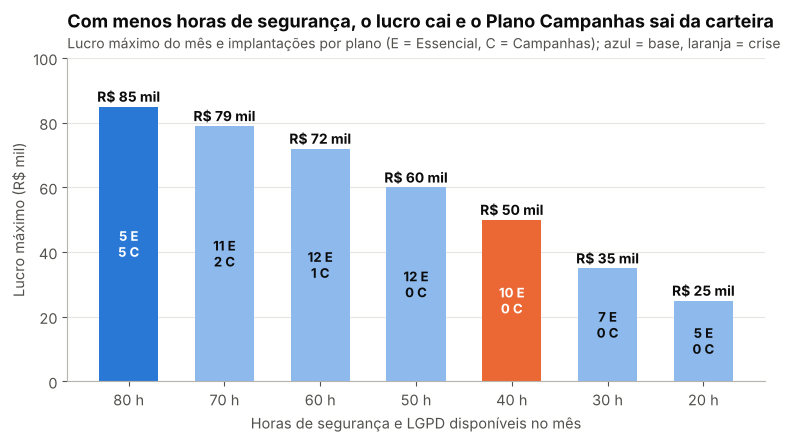

In [7]:
# Sensibilidade: lucro máximo para diferentes horas de segurança disponíveis
linhas = []
for horas in [80, 70, 60, 50, 40, 30, 20]:
    m, a, b = resolver_problema1(dict(DISPONIVEL, **{'Segurança e LGPD': horas}))
    linhas.append([horas, int(a.varValue), int(b.varValue), value(m.objective)])
sens_p1 = pd.DataFrame(linhas, columns=['Horas de segurança', 'Essencial', 'Campanhas', 'Lucro máximo (R$)'])
display(sens_p1.assign(**{'Lucro máximo (R$)': [brl(v) for v in sens_p1['Lucro máximo (R$)']]}))

# Gráfico 9 — Barras: lucro máximo por horas de segurança disponíveis
fig, ax = plt.subplots(figsize=(9, 4.2))
cores = [AZUL if h == 80 else (LARANJA if h == HORAS_SEGURANCA_CRISE else AZUL_CLARO) for h in sens_p1['Horas de segurança']]
pos = range(len(sens_p1))
ax.bar(pos, sens_p1['Lucro máximo (R$)'] / 1000, color=cores, width=0.62)
for i, (_, l) in zip(pos, sens_p1.iterrows()):
    ax.text(i, l['Lucro máximo (R$)'] / 1000 + 1.5, f"R$ {l['Lucro máximo (R$)'] / 1000:.0f} mil", ha='center',
            fontsize=10, fontweight='bold', color=TEXTO)
    ax.text(i, l['Lucro máximo (R$)'] / 1000 / 2, f"{int(l['Essencial'])} E\n{int(l['Campanhas'])} C", ha='center', va='center',
            fontsize=9.5, color=TEXTO if cores[i] == AZUL_CLARO else 'white', fontweight='bold')
ax.set_xticks(list(pos), [f'{h} h' for h in sens_p1['Horas de segurança']])
ax.set_xlabel('Horas de segurança e LGPD disponíveis no mês')
ax.set_ylabel('Lucro máximo (R$ mil)')
ax.set_ylim(0, 100)
ax.set_axisbelow(True)
ax.grid(axis='x', visible=False)
ax.set_title('Com menos horas de segurança, o lucro cai e o Plano Campanhas sai da carteira', pad=22)
subtitulo(ax, 'Lucro máximo do mês e implantações por plano (E = Essencial, C = Campanhas); azul = base, laranja = crise')
salvar(fig, 'grafico9_sensibilidade_lucro_seguranca')
plt.show()

**O que o What-If mostra.** Com 40 horas de segurança, o modelo passa a aceitar **10 implantações do Essencial e nenhuma do Campanhas**, e o lucro cai **41%**, para **R$ 50.000,00**. O desenvolvimento fica com 150 horas sobrando, mas sem horas de segurança não adianta vender o plano que trata a localização dos doadores: fazer isso significaria implantar sem os controles de acesso da Disciplina 3. A tabela de sensibilidade mostra quanto vale cada hora desse gargalo: cada 10 horas de segurança a menos custam entre R$ 6.000 e R$ 15.000 de lucro no mês, o que justifica manter um profissional de segurança de reserva.

## 4.2 Problema 2: Minimização de custos (transporte)

**Contexto.** A Disciplina 2 mostrou que os cadastros feitos em campanhas presenciais são os que menos localizam, principalmente por CEP ausente ou inválido. Para atacar esse gargalo, a Conecta Sangue vai mandar **agentes de cadastro** — funcionários treinados que conferem o CEP e o endereço na hora — aos mutirões das campanhas presenciais de dezembro nas três zonas com mais cadastros presenciais no piloto: **Leste, Sul e Norte**.

Os agentes ficam em duas bases: a **Base Centro** (junto ao Hemocentro Centro) e a **Base Oeste** (junto ao Hemocentro Oeste). O deslocamento de cada agente tem um custo diferente conforme a base e a zona. A gerência precisa decidir **quantos agentes enviar de cada base para cada mutirão, com o menor custo total de deslocamento**.

**Variáveis de decisão** (inteiras): $x_{ij}$ = quantidade de agentes enviados da base $i$ para o mutirão da zona $j$.

**Função objetivo** (custo total de deslocamento, em reais):

$$\text{Min } Z = \sum_{i=1}^{2}\sum_{j=1}^{3} c_{ij}\,x_{ij}$$

onde $c_{ij}$ é o custo de deslocamento de um agente da base $i$ até a zona $j$ (ida e volta).

**Restrições técnicas:**

* **Oferta:** o total de agentes enviados por uma base não pode passar do número de agentes da base: $\sum_j x_{ij} \le \text{oferta}_i$.
* **Demanda:** cada mutirão recebe exatamente os agentes de que precisa: $\sum_i x_{ij} = \text{demanda}_j$.
* **Lógica:** $x_{ij} \ge 0$ e inteiros.

In [8]:
# Dados do Problema 2
# Cadastros feitos em campanhas presenciais no piloto, por zona (base tratada da Disciplina 2)
CADASTROS_PRESENCIAIS = {'Leste': 143, 'Sul': 103, 'Norte': 49}
CADASTROS_POR_AGENTE = 25   # premissa: um agente confere até 25 cadastros por dia de mutirão

# Localizações (latitude, longitude) da base de pontos de coleta da Disciplina 2
BASES = {'Base Centro': (-23.558029, -46.635846),    # Hemocentro Centro (P001)
         'Base Oeste': (-23.544539, -46.752778)}     # Hemocentro Oeste (P010)
MUTIROES = {'Leste': (-23.5680, -46.5007),           # centro médio dos pontos de coleta de cada zona
            'Sul': (-23.6932, -46.6421),
            'Norte': (-23.4508, -46.6376)}
OFERTA = {'Base Centro': 9, 'Base Oeste': 7}         # agentes disponíveis em cada base (premissa)

# Premissas do custo: transporte por aplicativo, ida e volta
TARIFA_BASE, TARIFA_KM, FATOR_ROTA = 5.00, 2.00, 1.3  # R$ fixos, R$ por km, ruas x linha reta


def distancia_km(a, b):
    """Distância em linha reta entre dois pontos (fórmula de Haversine)."""
    la1, lo1, la2, lo2 = map(math.radians, [*a, *b])
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371 * math.asin(math.sqrt(h))


DEMANDA = {z: math.ceil(n / CADASTROS_POR_AGENTE) for z, n in CADASTROS_PRESENCIAIS.items()}
DIST = {(i, j): distancia_km(BASES[i], MUTIROES[j]) for i in BASES for j in MUTIROES}
CUSTO = {(i, j): round(2 * (TARIFA_BASE + TARIFA_KM * FATOR_ROTA * d), 2) for (i, j), d in DIST.items()}

tabela_custos = pd.DataFrame([[CUSTO[i, j] for j in MUTIROES] + [OFERTA[i]] for i in BASES],
                             index=list(BASES), columns=[f'Zona {j}' for j in MUTIROES] + ['Oferta (agentes)'])
tabela_custos.loc['Demanda (agentes)'] = [DEMANDA[j] for j in MUTIROES] + [sum(DEMANDA.values())]
print('Custo de deslocamento por agente (R$, ida e volta), oferta e demanda:')
display(tabela_custos)
print('Distâncias em linha reta (km):', {f'{i} → {j}': round(d, 1) for (i, j), d in DIST.items()})

Custo de deslocamento por agente (R$, ida e volta), oferta e demanda:


,Zona Leste,Zona Sul,Zona Norte,Oferta (agentes)
Base Centro,81.86,88.23,72.01,9
Base Oeste,144.30,114.05,91.66,7
Demanda (agentes),6.00,5.00,2.00,13


Distâncias em linha reta (km): {'Base Centro → Leste': 13.8, 'Base Centro → Sul': 15.0, 'Base Centro → Norte': 11.9, 'Base Oeste → Leste': 25.8, 'Base Oeste → Sul': 20.0, 'Base Oeste → Norte': 15.7}


In [9]:
def resolver_problema2(oferta=OFERTA, demanda=DEMANDA):
    """Monta e resolve o modelo de transporte. Devolve o modelo e as variáveis x[i][j]."""
    modelo = LpProblem(name='Min_Custo_Agentes', sense=LpMinimize)

    # Variáveis de decisão: agentes enviados da base i para a zona j (inteiros)
    x = LpVariable.dicts('Agentes', (list(BASES), list(MUTIROES)), lowBound=0, cat='Integer')

    # Função objetivo: custo total de deslocamento
    modelo += lpSum(CUSTO[i, j] * x[i][j] for i in BASES for j in MUTIROES), 'Custo_total'

    # Oferta: cada base envia no máximo os agentes que tem
    for i in BASES:
        modelo += (lpSum(x[i][j] for j in MUTIROES) <= oferta[i], f'Oferta_{i.replace(" ", "_")}')

    # Demanda: cada mutirão recebe exatamente os agentes de que precisa
    for j in MUTIROES:
        modelo += (lpSum(x[i][j] for i in BASES) == demanda[j], f'Demanda_{j}')

    modelo.solve(PULP_CBC_CMD(msg=False))
    return modelo, x


def plano(x):
    """Tabela com a quantidade de agentes de cada base para cada zona."""
    return pd.DataFrame([[int(x[i][j].varValue) for j in MUTIROES] for i in BASES],
                        index=list(BASES), columns=[f'Zona {j}' for j in MUTIROES])

In [10]:
# Resolução do cenário base
modelo2, x = resolver_problema2()
p2_base = {'status': LpStatus[modelo2.status], 'custo': value(modelo2.objective)}
plano_p2_base = plano(x)

print(f"Status: {p2_base['status']}")
print('Plano ótimo (agentes enviados):')
display(plano_p2_base)
print(f"Custo mínimo de deslocamento: {brl(p2_base['custo'])}")

Status: Optimal
Plano ótimo (agentes enviados):


,Zona Leste,Zona Sul,Zona Norte
Base Centro,6,3,0
Base Oeste,0,2,2


Custo mínimo de deslocamento: R$ 1.167,27


**Leitura do resultado.** O modelo manda **os 6 agentes da Zona Leste a partir da Base Centro** — a Leste é a zona mais longe da Base Oeste — e completa os mutirões do Sul (3 da Base Centro e 2 da Base Oeste) e do Norte (2 da Base Oeste). O custo mínimo é de **R$ 1.167,27** por dia de mutirão. A Base Centro usa todos os seus 9 agentes, e a Base Oeste fica com 3 de reserva. A prioridade para a Zona Leste é coerente com a Disciplina 2, que mostrou a Leste como a zona com mais cadastros presenciais e com a maior distância até os pontos de coleta.

### Análise de cenário (What-If) — Problema 2

**Cenário de crise:** e se **três agentes da Base Centro adoecerem** na semana do mutirão e a oferta da base cair de **9 para 6**? Altere o valor de `AGENTES_CENTRO_CRISE` e execute a célula de novo para testar outros cenários.

In [11]:
AGENTES_CENTRO_CRISE = 6

oferta_crise = dict(OFERTA, **{'Base Centro': AGENTES_CENTRO_CRISE})
modelo2_crise, x_c = resolver_problema2(oferta_crise)
p2_crise = {'status': LpStatus[modelo2_crise.status],
            'custo': value(modelo2_crise.objective) if modelo2_crise.status == 1 else None}

print(f"Status: {p2_crise['status']}")
if modelo2_crise.status == 1:
    plano_p2_crise = plano(x_c)
    display(plano_p2_crise)
    aumento = p2_crise['custo'] / p2_base['custo'] - 1
    aumento_txt = f'{aumento * 100:.1f}'.replace('.', ',')
    print(f"Custo mínimo na crise: {brl(p2_crise['custo'])} (+{aumento_txt}% em relação ao cenário base)")
else:
    print('Sem solução viável: faltam agentes para cobrir a demanda dos mutirões.')

Status: Optimal


,Zona Leste,Zona Sul,Zona Norte
Base Centro,6,0,0
Base Oeste,0,5,2


Custo mínimo na crise: R$ 1.244,73 (+6,6% em relação ao cenário base)


,Agentes na Base Centro,Status,Custo mínimo (R$)
0,9,Optimal,"R$ 1.167,27"
1,8,Optimal,"R$ 1.193,09"
2,7,Optimal,"R$ 1.218,91"
3,6,Optimal,"R$ 1.244,73"
4,5,Infeasible,sem solução
5,4,Infeasible,sem solução


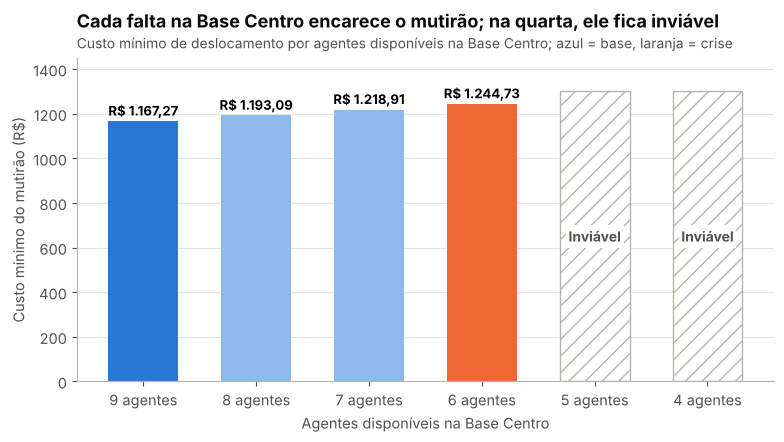

In [12]:
# Sensibilidade: custo mínimo conforme os agentes disponíveis na Base Centro (Base Oeste com 7)
linhas = []
for agentes in [9, 8, 7, 6, 5, 4]:
    m, _ = resolver_problema2(dict(OFERTA, **{'Base Centro': agentes}))
    linhas.append([agentes, LpStatus[m.status], round(value(m.objective), 2) if m.status == 1 else None])
sens_p2 = pd.DataFrame(linhas, columns=['Agentes na Base Centro', 'Status', 'Custo mínimo (R$)'])
display(sens_p2.assign(**{'Custo mínimo (R$)': [brl(v) if pd.notna(v) else 'sem solução' for v in sens_p2['Custo mínimo (R$)']]}))

# Gráfico 10 — Barras: custo mínimo por agentes disponíveis na Base Centro
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (_, l) in enumerate(sens_p2.iterrows()):
    if l['Status'] == 'Optimal':
        cor = AZUL if l['Agentes na Base Centro'] == 9 else (LARANJA if l['Agentes na Base Centro'] == AGENTES_CENTRO_CRISE else AZUL_CLARO)
        ax.bar(i, l['Custo mínimo (R$)'], color=cor, width=0.62)
        ax.text(i, l['Custo mínimo (R$)'] + 25, brl(l['Custo mínimo (R$)']), ha='center', fontsize=9.5, fontweight='bold')
    else:
        ax.bar(i, 1300, color='white', edgecolor='#b5b4ad', hatch='//', width=0.62)
        ax.text(i, 650, 'Inviável', ha='center', va='center', fontsize=10, fontweight='bold', color=TEXTO_SECUNDARIO,
                bbox=dict(facecolor='white', edgecolor='none', pad=2))
ax.set_xticks(range(len(sens_p2)), [f'{a} agentes' for a in sens_p2['Agentes na Base Centro']])
ax.set_xlabel('Agentes disponíveis na Base Centro')
ax.set_ylabel('Custo mínimo do mutirão (R$)')
ax.set_ylim(0, 1450)
ax.set_axisbelow(True)
ax.grid(axis='x', visible=False)
ax.set_title('Cada falta na Base Centro encarece o mutirão; na quarta, ele fica inviável', pad=22)
subtitulo(ax, 'Custo mínimo de deslocamento por agentes disponíveis na Base Centro; azul = base, laranja = crise')
salvar(fig, 'grafico10_sensibilidade_custo_agentes')
plt.show()

**O que o What-If mostra.** Com 6 agentes na Base Centro, o modelo continua cobrindo os três mutirões: a Base Centro fica só com a Zona Leste, e a Base Oeste assume todo o Sul e o Norte. O custo sobe **6,6%**, para **R$ 1.244,73**. A tabela de sensibilidade mostra o limite: cada falta custa cerca de R$ 25,82 a mais, porque um agente passa a sair da Base Oeste, mais distante do Sul. Com **4 faltas** (5 agentes na Base Centro), não há solução viável: a soma das duas bases (12 agentes) fica abaixo da demanda (13). A gerência sabe, antes da campanha, que precisa de pelo menos 6 agentes na Base Centro ou de um plano de contingência.

## Conferência independente dos resultados

Para garantir que os números não dependem de um único resolvedor, a célula abaixo resolve os mesmos quatro cenários com o `scipy.optimize.milp` (resolvedor HiGHS), que já vem no Colab, e compara com os resultados do PuLP.

In [13]:
import numpy as np
from scipy.optimize import milp, LinearConstraint, Bounds


def conferir_p1(disponivel):
    c = -np.array([LUCRO['Essencial'], LUCRO['Campanhas']])                    # milp minimiza: usa -lucro
    A = [[HORAS[r]['Essencial'], HORAS[r]['Campanhas']] for r in HORAS] + [[1, 0], [0, 1]]
    b = [disponivel[r] for r in HORAS] + [MERCADO['Essencial'], MERCADO['Campanhas']]
    r = milp(c, constraints=LinearConstraint(A, -np.inf, b), integrality=[1, 1], bounds=Bounds(0, np.inf))
    return -r.fun


def conferir_p2(oferta):
    pares = [(i, j) for i in BASES for j in MUTIROES]
    c = np.array([CUSTO[p] for p in pares])
    A_of = [[1 if p[0] == i else 0 for p in pares] for i in BASES]
    A_de = [[1 if p[1] == j else 0 for p in pares] for j in MUTIROES]
    r = milp(c, constraints=[LinearConstraint(A_of, -np.inf, [oferta[i] for i in BASES]),
                             LinearConstraint(A_de, [DEMANDA[j] for j in MUTIROES], [DEMANDA[j] for j in MUTIROES])],
             integrality=np.ones(len(pares)), bounds=Bounds(0, np.inf))
    return r.fun if r.success else None


conferencia = pd.DataFrame([
    ['Problema 1 — base', brl(p1_base['lucro']), brl(conferir_p1(DISPONIVEL))],
    ['Problema 1 — crise', brl(p1_crise['lucro']), brl(conferir_p1(disponivel_crise))],
    ['Problema 2 — base', brl(p2_base['custo']), brl(conferir_p2(OFERTA))],
    ['Problema 2 — crise', brl(p2_crise['custo']), brl(conferir_p2(oferta_crise))],
], columns=['Cenário', 'PuLP (CBC)', 'SciPy (HiGHS)'])
display(conferencia)
assert (conferencia['PuLP (CBC)'] == conferencia['SciPy (HiGHS)']).all()
print('Conferência OK: os dois resolvedores chegam aos mesmos valores ótimos.')

,Cenário,PuLP (CBC),SciPy (HiGHS)
0,Problema 1 — base,"R$ 85.000,00","R$ 85.000,00"
1,Problema 1 — crise,"R$ 50.000,00","R$ 50.000,00"
2,Problema 2 — base,"R$ 1.167,27","R$ 1.167,27"
3,Problema 2 — crise,"R$ 1.244,73","R$ 1.244,73"


Conferência OK: os dois resolvedores chegam aos mesmos valores ótimos.


In [14]:
# Resumo dos resultados (usado no Documento Final)
RESUMO = {
    'p1_base': p1_base, 'p1_crise': p1_crise, 'p1_horas_crise': HORAS_SEGURANCA_CRISE,
    'p1_queda': 1 - p1_crise['lucro'] / p1_base['lucro'],
    'p1_uso_base': uso_p1_base.reset_index().values.tolist(), 'p1_uso_crise': uso_p1_crise.reset_index().values.tolist(),
    'p1_sens': sens_p1.values.tolist(),
    'p2_base': p2_base, 'p2_crise': p2_crise, 'p2_agentes_crise': AGENTES_CENTRO_CRISE,
    'p2_aumento': p2_crise['custo'] / p2_base['custo'] - 1,
    'p2_plano_base': plano_p2_base.reset_index().values.tolist(), 'p2_plano_crise': plano_p2_crise.reset_index().values.tolist(),
    'p2_custos': {f'{i}|{j}': c for (i, j), c in CUSTO.items()}, 'p2_dist': {f'{i}|{j}': round(d, 1) for (i, j), d in DIST.items()},
    'p2_demanda': DEMANDA, 'p2_oferta': OFERTA, 'p2_sens': sens_p2.values.tolist(),
}
print('Problema 1:', p1_base, '| crise:', p1_crise)
print('Problema 2:', p2_base, '| crise:', p2_crise)

Problema 1: {'status': 'Optimal', 'essencial': 5, 'campanhas': 5, 'lucro': 85000.0} | crise: {'status': 'Optimal', 'essencial': 10, 'campanhas': 0, 'lucro': 50000.0}
Problema 2: {'status': 'Optimal', 'custo': 1167.27} | crise: {'status': 'Optimal', 'custo': 1244.73}
